In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [2]:
def mostrar(imgs, titulos):
    plt.figure(figsize=(12, 4))
    for i in range(3):
        plt.subplot(1, 3, i+1)
        plt.imshow(imgs[i], cmap='gray' if i < 2 else None)
        plt.title(titulos[i])
        plt.axis('off')
    plt.show()

In [3]:
def segmentar(img, bloco=101, c=-10, area=500):
    suave = cv2.GaussianBlur(img, (5, 5), 0)
    binaria = cv2.adaptiveThreshold(suave, 255,
                cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                cv2.THRESH_BINARY, bloco, c)

    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL,
                                    cv2.CHAIN_APPROX_SIMPLE)
    contornos = [x for x in contornos if cv2.contourArea(x) > area]

    semantica = np.zeros_like(img)
    instancias = np.zeros((img.shape[0], img.shape[1], 3), dtype=np.uint8)
    np.random.seed(10)

    for contorno in contornos:
        cv2.drawContours(semantica, [contorno], -1, 255, -1)
        cor = np.random.randint(50, 256, 3).tolist()
        cv2.drawContours(instancias, [contorno], -1, cor, -1)

    mostrar([img, semantica, instancias],
            ['Entrada', 'Semântica (1 classe)', 'Instância (1 cor por objeto)'])
    print('Objetos identificados:', len(contornos))

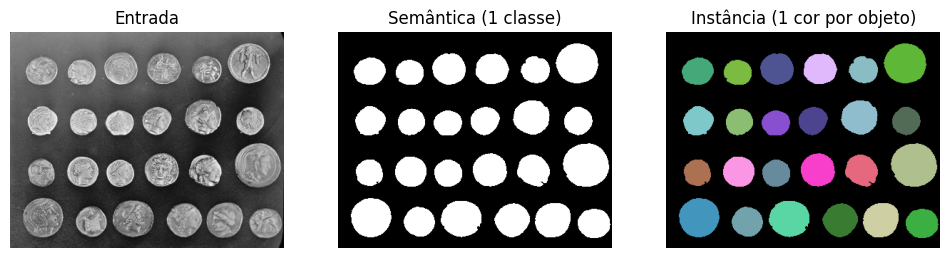

Objetos identificados: 24


In [4]:
moedas = data.coins()
segmentar(moedas)

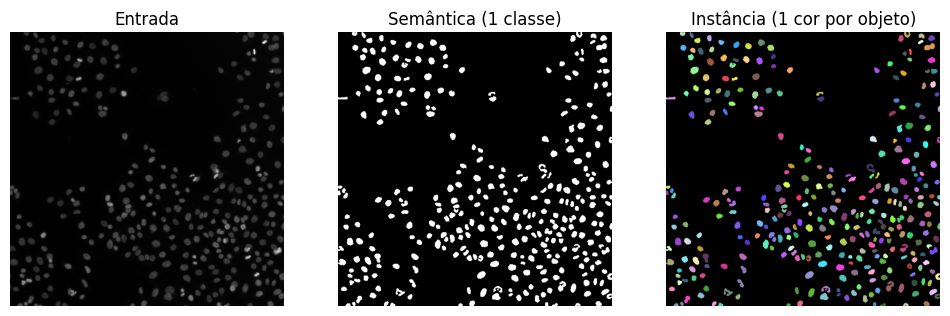

Objetos identificados: 317


In [20]:
celulas = data.human_mitosis()
segmentar(celulas, bloco=11, c=-2, area=20)

# Análise

Na imagem das moedas (data.coins()), a segmentação apresentou melhores resultados, pois os objetos são maiores e possuem contornos mais definidos, facilitando sua identificação individual.

Já na imagem data.human_mitosis(), a segmentação é mais difícil devido à presença de estruturas pequenas e próximas umas das outras. Isso pode fazer com que algumas sejam identificadas como um único objeto ou não sejam detectadas corretamente.

Conclusão: houve diferença entre as segmentações, sendo a das moedas mais simples e a das células mais desafiadora devido ao tamanho e à proximidade dos objetos.